# Statistics of trashnet

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lrivals/EmbeddedComputervision/blob/main/notebooks/trashnet/trashnet_stats.ipynb)

Presentation and statistical analysis of the dataset, read from the point of view of
Tiny-YOLO and the embedded target (input 416, 13×13 and 26×26 grids, 256 slots of
`yolo_post`, INT8). Tasks: [T32.2](../../docs/tasks/M32-trashnet-pets.md), [T32.10](../../docs/tasks/M32-trashnet-pets.md), [T16.4](../../docs/tasks/M16-presentation-jeux.md); milestone:
[M16](../../docs/tasks/M16-presentation-jeux.md); synthesis:
[stats-jeux.md](../../docs/tasks/stats-jeux.md). Other notebooks of the dataset:
[tiny-yolov3-trashnet_infer](tiny-yolov3-trashnet_infer.ipynb), [tiny-yolov3-trashnet_train](tiny-yolov3-trashnet_train.ipynb), [tiny-yolov3-trashnet_sweep](tiny-yolov3-trashnet_sweep.ipynb), [tiny-yolov4-trashnet_infer](tiny-yolov4-trashnet_infer.ipynb), [tiny-yolov4-trashnet_train](tiny-yolov4-trashnet_train.ipynb), [tiny-yolov4-trashnet_sweep](tiny-yolov4-trashnet_sweep.ipynb).

Tier: annotations **R** (whole split), pixels **M** (`SAMPLE = 200`
images per part). Prerequisites: data `data/trashnet/annotations_val.json` — tools/get_datasets.sh trashnet. No weights, no GPU.

Own question: How much of the image does one piece of waste cover, and which classes lose the most images to the labeller? (see: T32.8).

| | |
|---|---|
| source | https://github.com/garythung/trashnet |
| version | dataset-resized.zip (2017); boxes from the M22 labeller, Grounding DINO tiny (tools/prep_datasets.py trashnet) |
| licence | MIT (repository) |
| sensor | phone photos, one piece of waste on a white or light plain background |
| typical resolution | 512×384 |
| official `train` | — images, — objects |
| official `val` | — images, — objects |
| official `test` | — images, — objects |
| loader | the boxes are auto-labels: val and test measure agreement with the labeller, not with a human (hand-checked val subset: T32.3) |
| loader | images with no box ≥ TRASHNET_CONF left out (`data/trashnet/rejected.json`); boxes over the whole photo kept (close-ups where the object fills the frame) |
| loader | no official split: 70 / 15 / 15 stratified by class, fixed seed; photos of one object from several angles may sit on both sides |

No computation here: `tools/data_stats.py` computes (`stats.json`, `stats.md`,
gallery), `tools/figures/donnees.py` plots; each step prints the command. Outputs in
`build/notebooks/trashnet/stats/`, never in `results/`. Notebook generated by `python -m tools.notebooks`
(`make notebooks`): edit `tools/notebooks/gabarits.py`, not this file.

## Parameters

In [1]:
DATASET   = 'trashnet'  # key of DATASETS
SPLITS    = None  # list of splits; None: train then test splits of the dataset
SIZE      = None  # S or 'WxH'; None: input of the cfg of the dataset (416 otherwise)
RESIZE    = 'letterbox'  # letterbox | stretch (quantities seen by the network)
SAMPLE    = 200  # images read for the pixels, per part; 0: none
GALLERY   = 8  # gallery images per split
SEED      = 0  # draw of the images (pixels, gallery, scatter plots)
NET       = 'build/m11/cfg/tiny-yolov3-trashnet.cfg'  # cfg whose anchors and grids are used for the collisions
DEVICE    = 'cpu'  # CPU kernel: nothing runs on GPU
DATA_ROOT = None  # dataset root; None: data/<dataset> (Colab: Drive folder)
DRIVE_DIR = '/content/drive/MyDrive/EmbeddedCV'  # Colab: archives data/<dataset>.tar; None: no Drive
OUT       = 'build/notebooks/trashnet/stats'  # notebook outputs
REPO_URL  = 'https://github.com/lrivals/EmbeddedComputervision.git'  # Colab: cloned repository
REV       = 'main'  # Colab: revision

## Environment

Local: nothing is installed or downloaded, the cell checks the prerequisites and
stops with the command to run. Colab: clone of the repository, installation, CuPy if
`DEVICE = "gpu"`, weights, then data by `colab.prepare_data` (archive
`<DRIVE_DIR>/data/<dataset>.tar` or direct download; ExDark and FLIR: archive only,
made on the PC by `tools/get_datasets.sh pack <dataset>`).

In [2]:
import os
import subprocess
import sys
from pathlib import Path

COLAB = "google.colab" in sys.modules


def repo_root():
    for d in (Path.cwd(), *Path.cwd().parents):
        if (d / "tools" / "notebooks" / "commandes.py").exists():
            return d
    return None


ROOT = repo_root()
if COLAB:
    if ROOT is None:
        ROOT = Path("/content/EmbeddedComputervision")
        if not ROOT.exists():
            subprocess.run(["git", "clone", REPO_URL, str(ROOT)], check=True)
    # Clone of an earlier session: reset to REV (notebook and code of the same commit).
    subprocess.run(["git", "-C", str(ROOT), "fetch", "-q", "origin", REV], check=True)
    subprocess.run(["git", "-C", str(ROOT), "checkout", "-q", "FETCH_HEAD"], check=True)
    for m in [m for m in sys.modules if m.split(".")[0] in ("tools", "yolo")]:
        del sys.modules[m]  # modules imported before the update
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e",
                    f"{ROOT}/python[data,plots]"], check=True)
    if DEVICE == "gpu":
        # CPU runtime: no driver, CuPy would say "cudaErrorInsufficientDriver".
        try:
            smi = subprocess.run(["nvidia-smi"], capture_output=True, text=True)
        except FileNotFoundError:
            smi = None
        if smi is None or smi.returncode != 0:
            raise RuntimeError("Colab runtime without a GPU: create a new Colab server "
                               "of GPU type (T4, L4 or A100), or DEVICE = 'cpu'")
        cuda = smi.stdout.split("CUDA Version:")[-1].split()[0]  # driver version
        cupy_pkg = "cupy-cuda13x" if int(cuda.split(".")[0]) >= 13 else "cupy-cuda12x"
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", cupy_pkg],
                       check=True)
elif ROOT is None:
    raise RuntimeError("repository root not found: open the notebook from notebooks/")
os.chdir(ROOT)
for p in (ROOT, ROOT / "python"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from tools.notebooks import commandes as C
from tools.notebooks import env

TRACE = env.trace(DEVICE)
env.check_device(DEVICE)
env.prepare(DATASET, (), None, DATA_ROOT, COLAB, hint='',
            drive_dir=DRIVE_DIR)
if str(NET).endswith(".cfg") and not env.restore_cfg(NET):
    print(f"cfg {NET} missing (tools/m11.sh {DATASET}-prep): anchors and grids of "
          "tiny-yolov3-coco for the collisions")
    NET = "tiny-yolov3-coco"
Path(OUT).mkdir(parents=True, exist_ok=True)

repository /home/leonard/Documents/Perso/EmbeddedComputervision @ 70058a0 (modified); Python 3.12.3; NumPy 2.4.2; backend cpu
data of trashnet: data/trashnet/annotations_val.json; weights: —
cfg build/m11/cfg/tiny-yolov3-trashnet.cfg missing (tools/m11.sh trashnet-prep): anchors and grids of tiny-yolov3-coco for the collisions


## Computation (T16.0)

`tools/data_stats.py` reads the annotations of each split (whole), reads the pixels
of `SAMPLE` images per part (drawn with `SEED`), draws the gallery and plots the
figures. The quantities "seen by the network" are computed after `RESIZE` to `SIZE`.

In [3]:
import json

from IPython.display import Image as Img, Markdown, display

from tools import data_stats as DS
from tools.notebooks.matrice import SPLIT_IMAGES, palier_stats
from yolo.models.tiny_yolo import load_cfg

if SIZE is None:
    _, h, w = load_cfg(NET)["input"]
    SIZE = h if h == w else f"{w}x{h}"
ann, px = palier_stats(DATASET, SAMPLE)
print(f"tier: annotations {ann}, pixels {px} ({SAMPLE} images per part); "
      f"input {SIZE} ({RESIZE}); cfg {NET}")
C.run(C.cmd_data_stats(DATASET, OUT, SPLITS, SIZE, RESIZE, NET, SAMPLE, GALLERY, SEED,
                       data_root=DATA_ROOT))
STATS = json.loads(Path(OUT, "stats.json").read_text())
FIG = Path(OUT, "figures")


def show(name):
    png = FIG / f"{name}.png"
    if png.exists():
        display(Img(filename=str(png)))


def table(fn):
    text = fn(STATS)
    if text:
        display(Markdown(text))

tier: annotations R, pixels M (200 images per part); input 416 (letterbox); cfg tiny-yolov3-coco
$ python tools/data_stats.py --dataset trashnet --size 416 --resize letterbox --net tiny-yolov3-coco --sample 200 --gallery 8 --seed 0 --figures --out build/notebooks/trashnet/stats


chargement trashnet train…


chargement trashnet test…


analyses train (1765 images)…


analyses test (379 images)…


...

→ build/notebooks/trashnet/stats/figures/intensites.png


→ build/notebooks/trashnet/stats/figures/ancres.png


→ build/notebooks/trashnet/stats/figures/ancres_k.png


→ build/notebooks/trashnet/stats/figures/ecart.png


  (36 s)


## Presentation and gallery (T16.4)

Classes of the dataset and their VOC and COCO mapping (`MAPPINGS`), then `GALLERY`
images per split, one image per class; ground truth drawn by `tools/detect.py:draw`.
At a fixed `SEED`, the gallery does not change.

| class | VOC | COCO |
|---|---|---|
| cardboard | — | — |
| glass | — | — |
| metal | — | — |
| paper | — | — |
| plastic | — | — |
| trash | — | — |

gallery: train


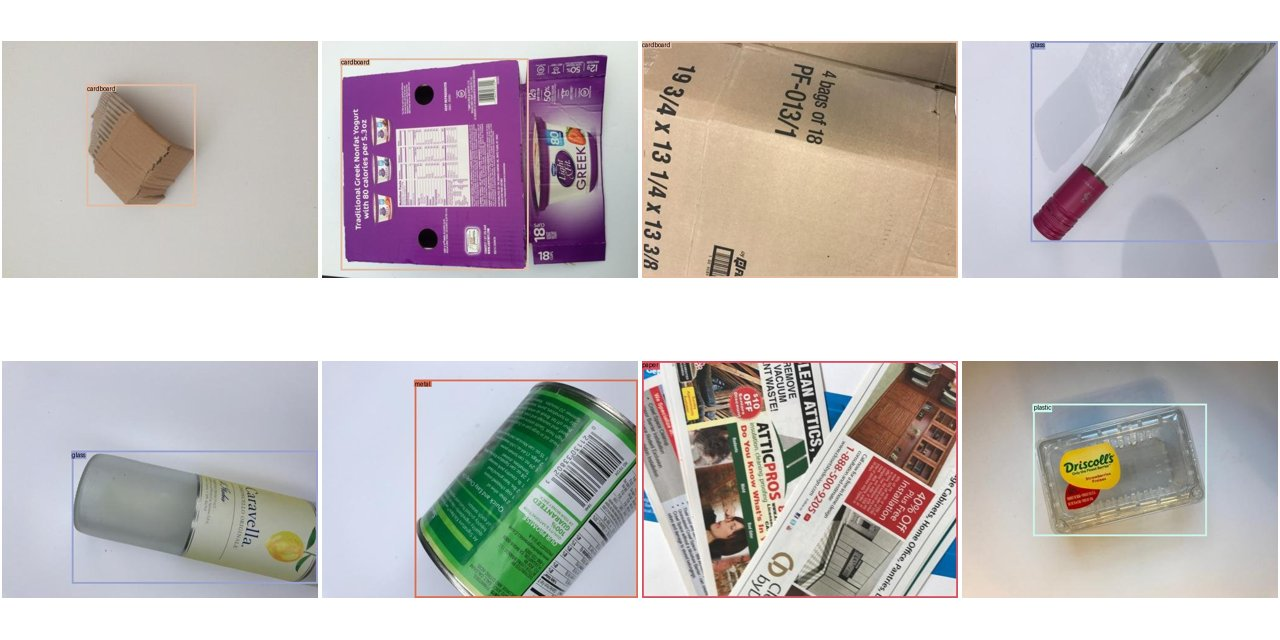

gallery: test


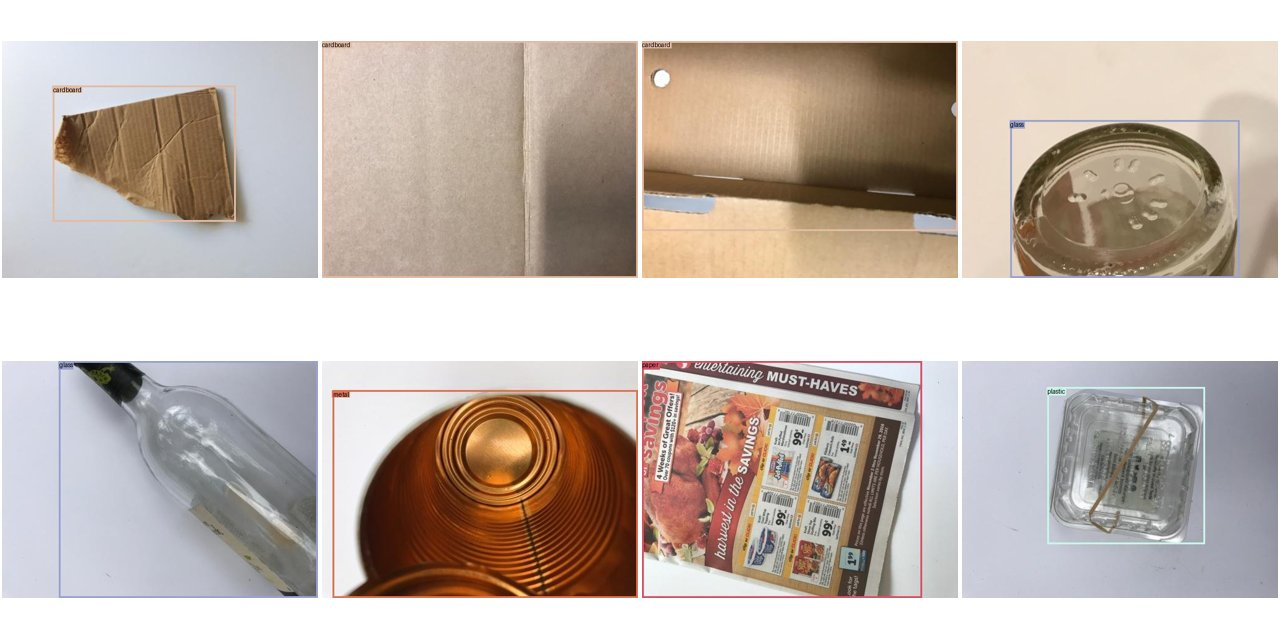

gallery: classes


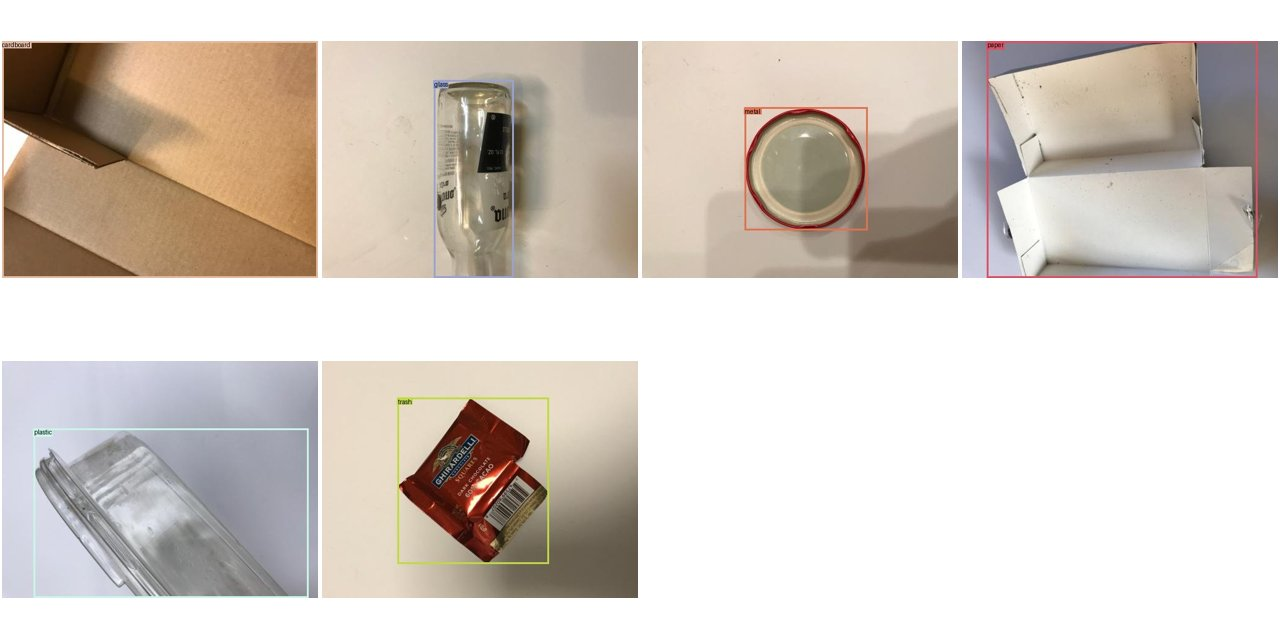

In [4]:
from yolo.data import datasets as D

rows = ["| class | VOC | COCO |", "|---|---|---|"]
for c in D.DATASETS[DATASET].classes:
    m = [c if DATASET == f else D.MAPPINGS.get((DATASET, f), {}).get(c, "—")
         for f in ("voc", "coco")]
    rows.append(f"| {c} | {m[0]} | {m[1]} |")
display(Markdown("\n".join(rows)))
for g, sheet in STATS.get("galerie", {}).get("planches", {}).items():
    if g != "suspectes":
        print(f"gallery: {g}")
        display(Img(filename=str(Path(OUT, sheet))))

## Counts and classes (T16.5)

Counts per split (annotations, whole split), against the official counts of the
datasheet; objects per class and co-occurrence.

| part | images | objects | difficult | empty images | objects/image (med. / max) | small < 32² at 416×416 | smaller than a cell | lost targets | images > 256 / > 1,024 |
|---|---|---|---|---|---|---|---|---|---|
| train | 1,765 | 1,765 | 0 | 0 | 1 / 1 | 0.0 % | 13x13 0.0 % · 26x26 0.0 % | 0.00 % | 0 / 0 |
| test | 379 | 379 | 0 | 0 | 1 / 1 | 0.3 % | 13x13 0.0 % · 26x26 0.0 % | 0.00 % | 0 / 0 |
| all | 2,144 | 2,144 | 0 | 0 | 1 / 1 | 0.0 % | 13x13 0.0 % · 26x26 0.0 % | 0.00 % | 0 / 0 |

train: 1765 images, 1765 objects; official — / —: ok
test: 379 images, 379 objects; official — / —: ok


| class | train: objects (images) | test: objects (images) | median side (px, letterbox) | small |
|---|---|---|---|---|
| cardboard | 283 (283) | 60 (60) | 360 | 0 % |
| glass | 351 (351) | 75 (75) | 234 | 0 % |
| metal | 286 (286) | 62 (62) | 247 | 0 % |
| paper | 412 (412) | 89 (89) | 293 | 0 % |
| plastic | 338 (338) | 72 (72) | 246 | 0 % |
| trash | 95 (95) | 21 (21) | 222 | 0 % |

Ratio of the most / least frequent class: 4.

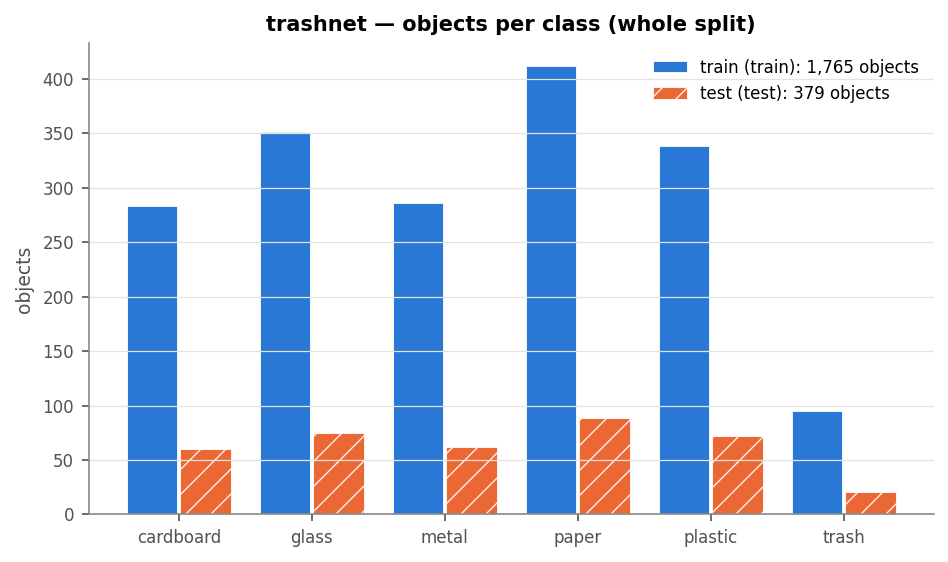

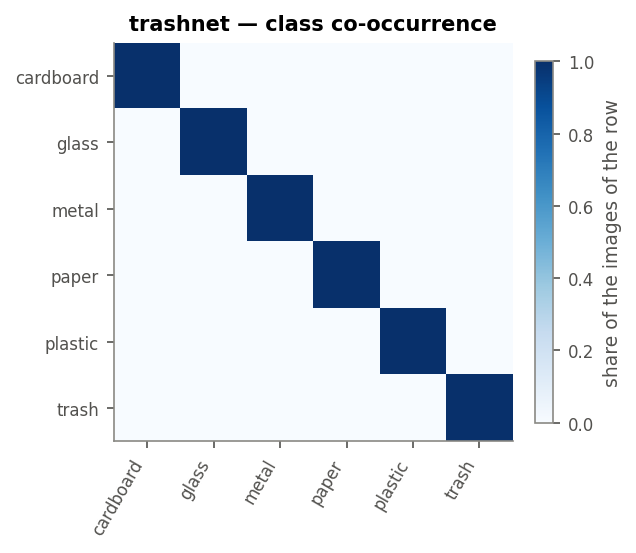

In [5]:
table(DS.md_synthese)
chk = DS.check_official(STATS)
for sp, i, o, (a, b), ok in chk:
    print(f"{sp}: {i} images, {o} objects; official {a or '—'} / {b or '—'}: "
          f"{'ok' if ok else 'gap (see the notes of the datasheet)'}")
table(DS.md_classes)
show("classes")
show("cooccurrence")

## Box geometry (T16.6)

Sizes in original and input pixels (letterbox and stretch at `SIZE`), COCO
categories before and after resizing, share of the objects smaller than a cell of
each head, box centres.

| frame | small | medium | large | median side (px) | smaller than a cell | height < 8 px |
|---|---|---|---|---|---|---|
| original image | 0.0 % | 1.4 % | 98.6 % | 324 | — | — |
| letterbox 416×416 | 0.0 % | 2.6 % | 97.3 % | 264 | 13x13 0.0 % · 26x26 0.0 % | 0.0 % |
| stretch 416×416 | 0.0 % | 1.6 % | 98.4 % | 304 | 13x13 0.0 % · 26x26 0.0 % | 0.0 % |

2,144 non-difficult objects; head strides: 13x13 → 32 px, 26x26 → 16 px.

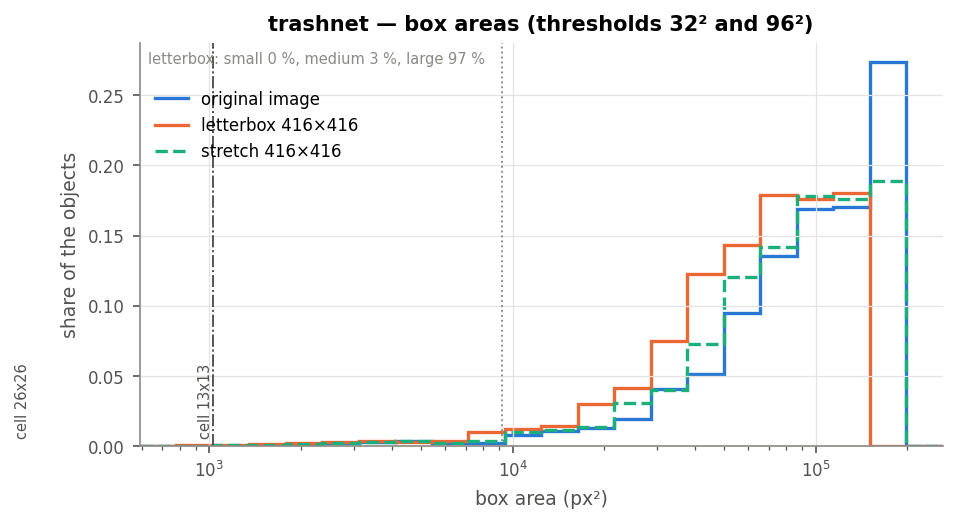

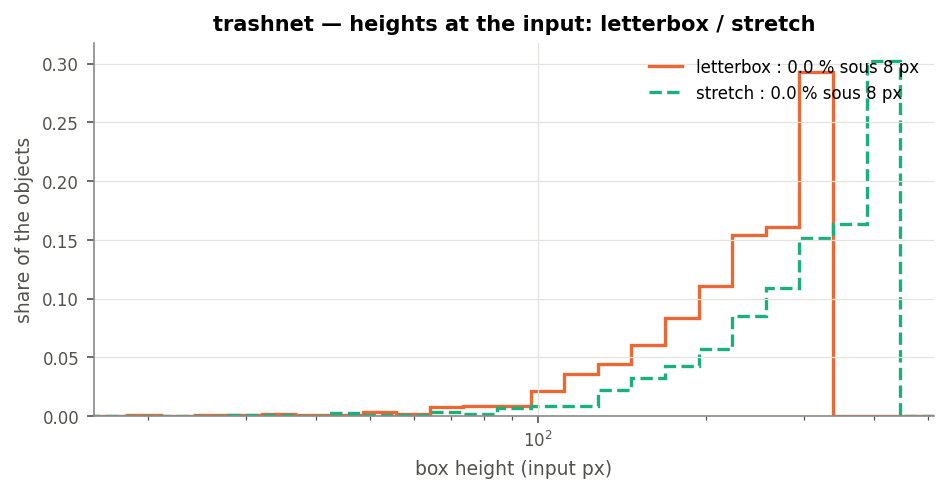

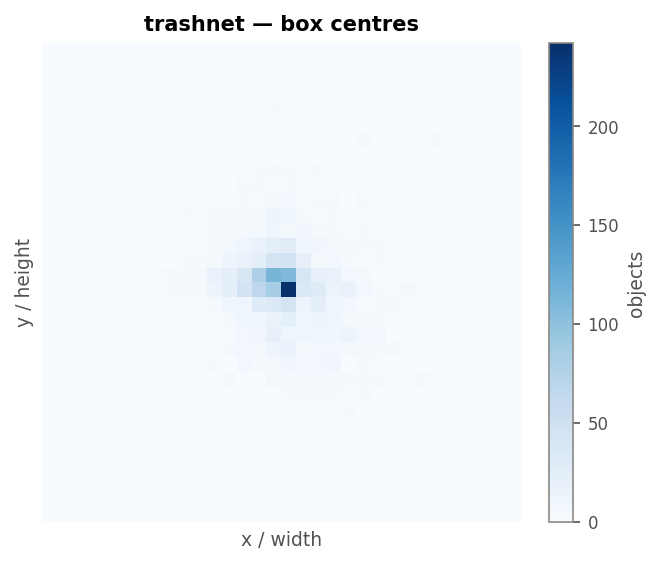

In [6]:
table(DS.md_geometrie)
show("tailles")
show("letterbox_stretch")
show("centres")

## Density and collisions (T16.7)

Objects per image against the 256 slots of `yolo_post`; targets lost when two
objects fall on the same cell and the same anchor (`build_targets`, anchors of `NET`).

| part | objects/image mean | med. | max | > 256 / > 1,024 | lost targets | per head (lost / objects) | images hit |
|---|---|---|---|---|---|---|---|
| train | 1.0 | 1 | 1 | 0 / 0 | 0 / 1,765 (0.00 %) | 13x13: 0 / 1,695 · 26x26: 0 / 70 | 0 |
| test | 1.0 | 1 | 1 | 0 / 0 | 0 / 379 (0.00 %) | 13x13: 0 / 362 · 26x26: 0 / 17 | 0 |
| all | 1.0 | 1 | 1 | 0 / 0 | 0 / 2,144 (0.00 %) | 13x13: 0 / 2,057 · 26x26: 0 / 87 | 0 |

Anchors of `tiny-yolov3-coco`; non-difficult objects, as in training.

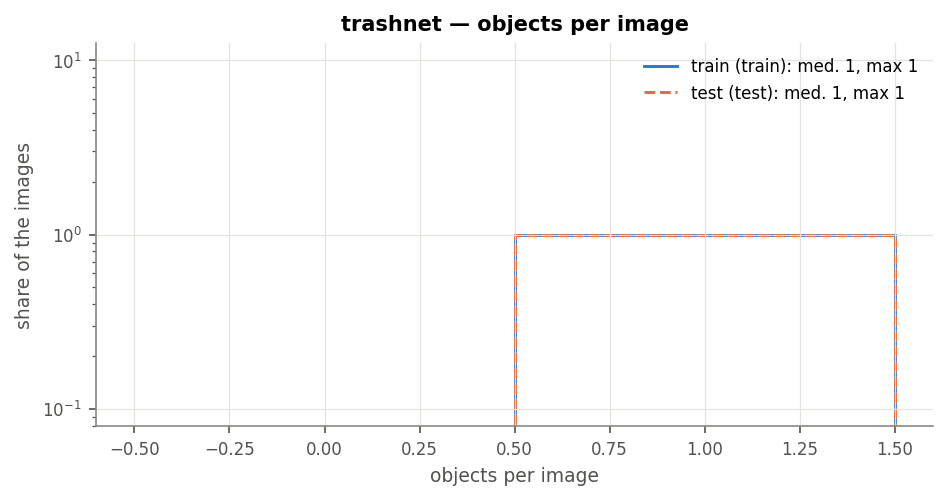

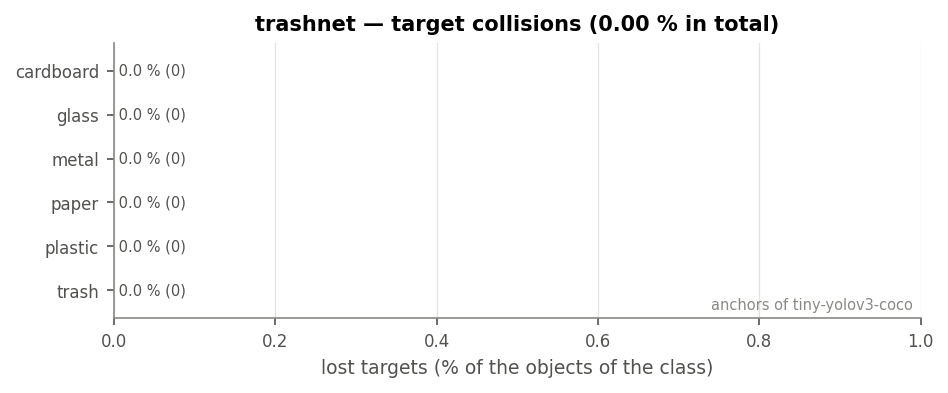

In [7]:
table(DS.md_densite)
show("densite")
show("collisions")

## Images (T16.8)

Resolutions on the whole split (annotations); channels, intensities and luminance on
`SAMPLE` images per part, against VOC2007 test (INT8 scales of M4).

| part | resolutions (first 3) | distinct | pixels on | channels | mean per channel | standard deviation per channel | mean luminance | 8-bit levels → INT8 |
|---|---|---|---|---|---|---|---|---|
| train | 512×384 (1,765) | 1 | 200 images | 3 | 170.7 / 164.4 / 156.2 | 54.3 / 52.7 / 58.3 | 165.4 | 256 → 128 |
| test | 512×384 (379) | 1 | 200 images | 3 | 172.1 / 163.5 / 154.7 | 52.9 / 53.6 / 59.9 | 165.1 | 256 → 128 |
| all | 512×384 (2,144) | 1 | 200 images | 3 | 170.9 / 161.4 / 152.1 | 53.7 / 54.4 / 59.6 | 163.2 | 256 → 128 |

VOC2007 test reference (200 images, seed 0): mean luminance 107.7, mean per channel 112.1 / 107.1 / 98.5.

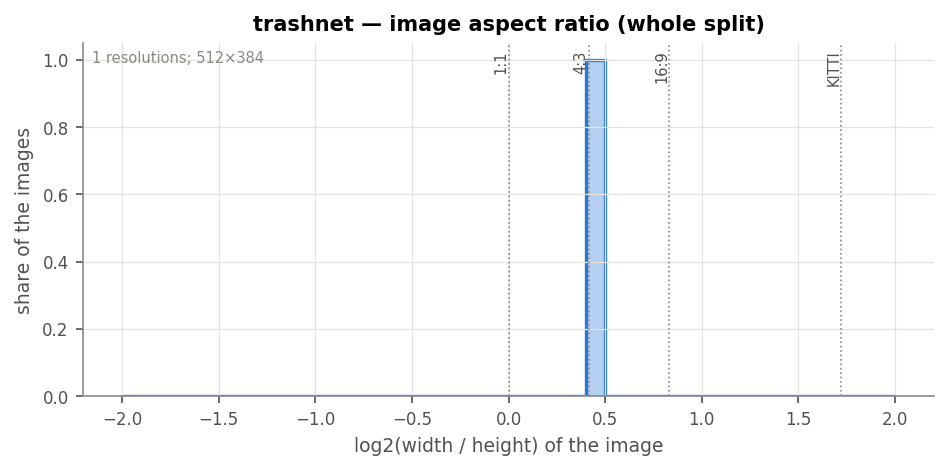

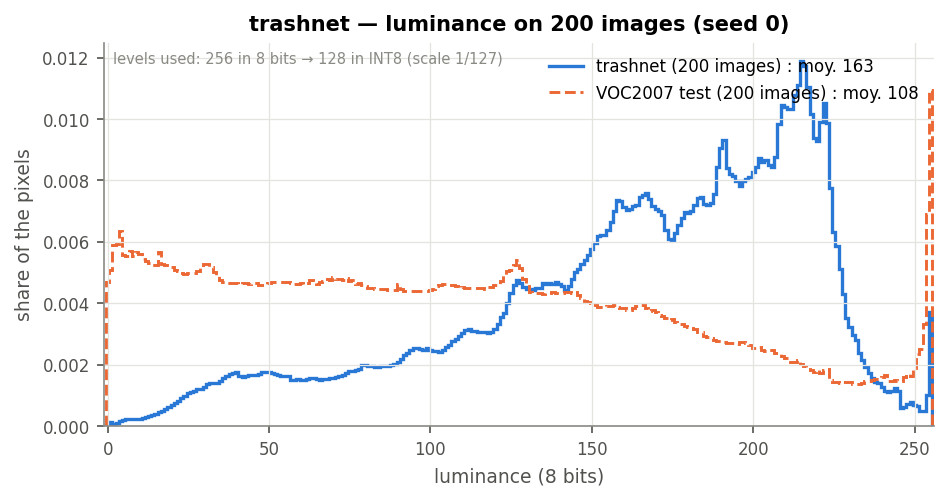

In [8]:
table(DS.md_images)
show("resolutions")
show("intensites")

## Anchors (T16.9)

Boxes of the train group in letterbox input pixels, anchors of the cfg, of VOC, of
COCO and of the k-means (`tools/kmeans_anchors.py`, same `--size` and `--seed`).

| anchors | w,h (px at 416×416) | mean IoU |
|---|---|---|
| VOC (tiny-yolov2-voc) | `35,38  109,141  212,364  301,164  532,337` | 0.6512 |
| VOC (tiny-yolov3-voc) | `10,14  23,27  37,58  81,82  135,169  344,319` | 0.6707 |
| COCO (tiny-yolov3-coco) | `10,14  23,27  37,58  81,82  135,169  344,319` | 0.6707 |
| cfg du jeu (tiny-yolov3-coco) | `10,14  23,27  37,58  81,82  135,169  344,319` | 0.6707 |
| k-means k = 5 (seed 0) | `112,106  185,208  314,155  274,259  387,293` | 0.7874 |
| k-means k = 6 (seed 0) | `104,101  179,207  282,134  259,264  348,211  386,302` | 0.8050 |

1,765 non-difficult boxes of the train group, letterbox 416×416.

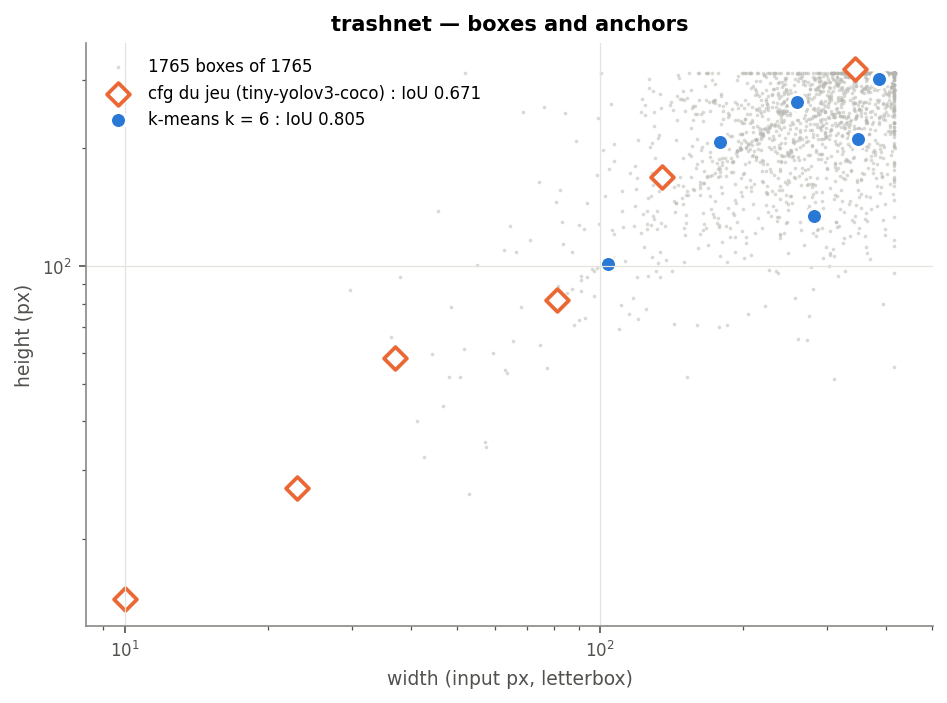

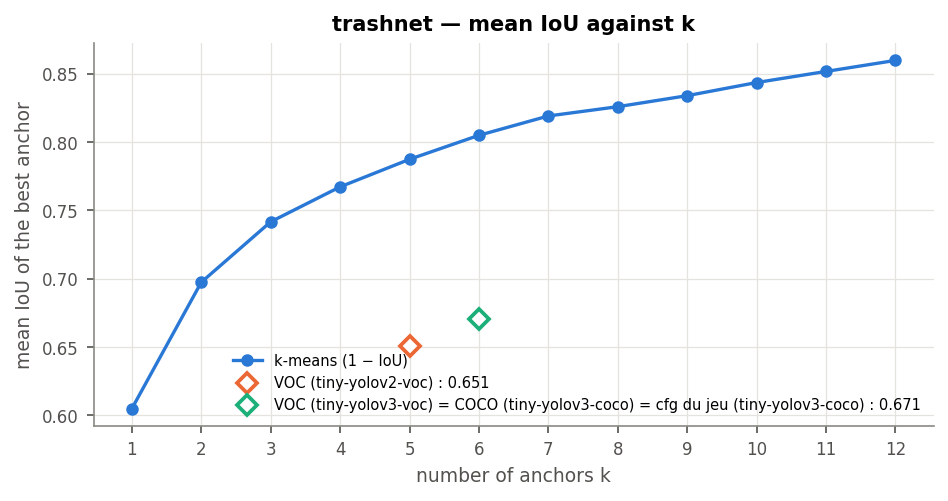

In [9]:
table(DS.md_ancres)
show("ancres")
show("ancres_k")

## Annotation quality (T16.10)

Boxes removed or clipped by the loader, degenerate, duplicates, regions removed;
the analysis reports, it does not correct (a correction goes through M11).

In [10]:
table(DS.md_qualite)
sus = DS.whole(STATS).get("qualite", {}).get("suspects", [])
for d in sus:
    print(f"{d['id']}: score {d['score']} (removed {d['retirées']}, clipped "
          f"{d['rognées']}, degenerate {d['dégénérées']}, duplicates {d['doublons']})")
sheet = STATS.get("galerie", {}).get("planches", {}).get("suspectes")
if sheet:
    display(Img(filename=str(Path(OUT, sheet))))

| part | removed (make_sample) | clipped | side < 2 px (orig. / input) | duplicates (IoU > 0.95) | regions removed by the loader |
|---|---|---|---|---|---|
| train | — | 0 | 0 / 0 | 0 | — |
| test | — | 0 | 0 / 0 | 0 | — |
| all | — | 0 | 0 / 0 | 0 | — |

## Gap between splits and out-of-domain coverage (T16.11)

Total variation distance between train and test, per quantity; share of the objects
that have a VOC or COCO class (what the out-of-domain notebooks of T14.5 evaluate).

| quantity (train ↔ test) | total variation |
|---|---|
| classes | 0.005 |
| area_in | 0.077 |
| w_in | 0.071 |
| h_in | 0.045 |
| aspect | 0.061 |
| per_image | 0.000 |

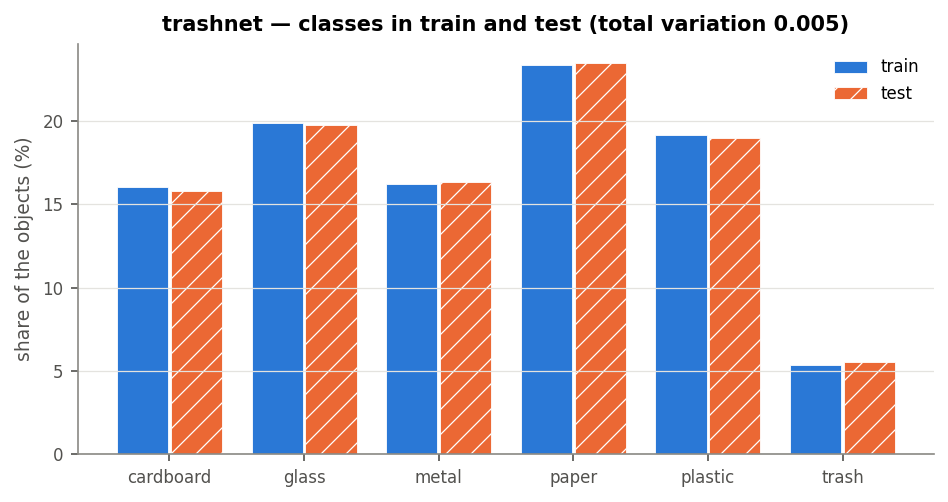

In [11]:
table(DS.md_ecart)
show("ecart")

## Own question of the dataset

How much of the image does one piece of waste cover, and which classes lose the most images to the labeller? (see: T32.8)

In [12]:
import json
from collections import Counter
from pathlib import Path
import numpy as np
from yolo.data.datasets import DATA_DIR
root = Path(DATA_ROOT or DATA_DIR / "trashnet")
kept = [e for s in ("train", "val", "test")
        for e in json.loads((root / f"annotations_{s}.json").read_text())]
cover = np.array([(b[2] - b[0]) * (b[3] - b[1]) / (e["width"] * e["height"])
                  for e in kept for b in e["boxes"]])
print(f"box share of the image: median {np.median(cover):.2f}, "
      f"q10 {np.quantile(cover, 0.1):.2f}, q90 {np.quantile(cover, 0.9):.2f}")
rej = json.loads((root / "rejected.json").read_text())
n = Counter(e["class"] for e in kept)
lost = Counter(r["class"] for r in rej)
print("left out by the labeller: " + ", ".join(
    f"{c} {lost[c]} / {n[c] + lost[c]} ({100 * lost[c] / (n[c] + lost[c]):.1f} %)"
    for c in sorted(n, key=lambda c: -lost[c] / (n[c] + lost[c]))))
print("reasons: " + ", ".join(f"{k} {v}" for k, v in
                              Counter(r["reason"] for r in rej).most_common()))
display(Markdown(DS.md_par_classe(STATS)))

box share of the image: median 0.54, q10 0.18, q90 1.00
left out by the labeller: paper 5 / 594 (0.8 %), cardboard 0 / 403 (0.0 %), glass 0 / 501 (0.0 %), metal 0 / 410 (0.0 %), plastic 0 / 482 (0.0 %), trash 0 / 137 (0.0 %)
reasons: no box 5


| class | objects (test, non-difficult) | share | median side (px) | small | lost targets |
|---|---|---|---|---|---|
| cardboard | 60 | 15.8 % | 346 | 2 % | 0.00 % |
| glass | 75 | 19.8 % | 237 | 0 % | 0.00 % |
| metal | 62 | 16.4 % | 251 | 0 % | 0.00 % |
| paper | 89 | 23.5 % | 304 | 0 % | 0.00 % |
| plastic | 72 | 19.0 % | 241 | 0 % | 0.00 % |
| trash | 21 | 5.5 % | 221 | 0 % | 0.00 % |

## Summary

In [13]:
table(DS.md_synthese)
print(f"outputs: {OUT}/ (stats.json, stats.md, figures/, galerie/); "
      f"revision {TRACE['rev']}")
print("equivalent commands:")
for c in C.HISTORY:
    print("  " + c)

| part | images | objects | difficult | empty images | objects/image (med. / max) | small < 32² at 416×416 | smaller than a cell | lost targets | images > 256 / > 1,024 |
|---|---|---|---|---|---|---|---|---|---|
| train | 1,765 | 1,765 | 0 | 0 | 1 / 1 | 0.0 % | 13x13 0.0 % · 26x26 0.0 % | 0.00 % | 0 / 0 |
| test | 379 | 379 | 0 | 0 | 1 / 1 | 0.3 % | 13x13 0.0 % · 26x26 0.0 % | 0.00 % | 0 / 0 |
| all | 2,144 | 2,144 | 0 | 0 | 1 / 1 | 0.0 % | 13x13 0.0 % · 26x26 0.0 % | 0.00 % | 0 / 0 |

outputs: build/notebooks/trashnet/stats/ (stats.json, stats.md, figures/, galerie/); revision 70058a0
equivalent commands:
  python tools/data_stats.py --dataset trashnet --size 416 --resize letterbox --net tiny-yolov3-coco --sample 200 --gallery 8 --seed 0 --figures --out build/notebooks/trashnet/stats
